# Assignment 01: Variational Autoencoder

In this assignment you implement a variational autoencoder (VAE) and train it on a small subset of MNIST: the digits 0, 1, 2, 3, 4 as gray images of 32 x 32 pixels, with 100 training images and 1000 test images per digit. The images come without labels.

**Do not modify this notebook.** It runs the code that you write, measures the trained model, and saves the results.

You write the files in the `code` folder:

| File | What you write |
|---|---|
| `code/myinfo.py` | your name and student ID |
| `code/mymodel.py` | the VAE: encoder, reparameterization, decoder |
| `code/myoptim.py` | batch size, number of epochs, optimizer |
| `code/mytrain.py` | loss function, training for one epoch |
| `code/mysample.py` | generation of new images |

Every part to write is marked with `TODO`, and the docstring of each function specifies its inputs and outputs. Keep these interfaces unchanged.

The files in the `util` folder are provided; do not modify them:

| File | What it provides |
|---|---|
| `util/data.py` | `get_dataset("train")` and `get_dataset("test")`: the training and the test images |
| `util/result.py` | `evaluate`: FID and reconstruction error of the trained model on the test images; `save`: writes them to a file |

The data files in the `data` folder are created by `util/prepare_data_mnist.py`.

Run all the cells from top to bottom (*Restart* and *Run All*). The notebook saves:

| File | Content |
|---|---|
| `train/loss.png`, `train/model.pt` | training curves, trained model |
| `sample/sample.png` | images generated by the trained model |
| `result/reconstruction.png` | test images and their reconstructions |
| `result/result_<student ID>_<name>.csv` | FID and reconstruction error |

> **Test copy of `assignment_01.ipynb` with GPU support.** It is the same notebook, with three changes:
>
> 1. **Setup**: the device is CUDA (NVIDIA, or AMD with a ROCm build of PyTorch), then MPS (Apple silicon), then **DirectML** (any DirectX 12 GPU on Windows, such as an AMD Radeon, with `pip install torch-directml`), then the CPU.
> 2. **Training**: `train/model.pt` is saved with the weights on the CPU, so that it can be loaded without DirectML.
> 3. **Results**: with DirectML, the FID is computed by `evaluate_on_device` in this notebook instead of `util/result.py`, because DirectML has no eigenvalue routine (`torch.linalg.eigvals`). The Inception-v3 network runs on the GPU; the enlargement of the images to 299 x 299 (the bilinear interpolation of DirectML gives different values), the statistics of the features and the Frechet distance are computed on the CPU, with the formulas of torcheval. The values are the same as those of `util/result.py` up to rounding. With CUDA, MPS or the CPU, `util/result.py` is used unchanged.
>
> The files are saved in the same folders as with the original notebook (`train`, `sample`, `result`), so they replace the files of the original notebook.

## Setup

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader

# The notebook is in the project folder, next to the folders code, util, data
ROOT = Path.cwd()
assert (ROOT / "code").is_dir() and (ROOT / "util").is_dir(), (
    f"run this notebook from the project folder, which contains code and util (now in {ROOT})")

# Make the files of code (yours) and util (provided) importable
for folder in ("code", "util"):
    if str(ROOT / folder) not in sys.path:
        sys.path.insert(0, str(ROOT / folder))

# Folders for the files saved by the notebook
TRAIN_DIR, SAMPLE_DIR, RESULT_DIR = ROOT / "train", ROOT / "sample", ROOT / "result"
for folder in (TRAIN_DIR, SAMPLE_DIR, RESULT_DIR):
    folder.mkdir(exist_ok=True)

SEED = 0
torch.manual_seed(SEED)

# GPU: NVIDIA or AMD with ROCm (cuda), Apple silicon (mps), any DirectX 12 GPU on
# Windows (DirectML, package torch-directml), else the CPU
try:
    import torch_directml
    HAS_DML = torch_directml.is_available()
except ImportError:
    HAS_DML = False

USE_DML = False
if torch.cuda.is_available():
    device = torch.device("cuda")
    device_name = ("ROCm" if getattr(torch.version, "hip", None) else "CUDA") + \
        f", {torch.cuda.get_device_name(0)}"
elif torch.backends.mps.is_available():
    device = torch.device("mps")
    device_name = "Apple silicon"
elif HAS_DML:
    device = torch_directml.device()
    device_name = f"DirectML, {torch_directml.device_name(0)}"
    USE_DML = True
else:
    device = torch.device("cpu")
    device_name = "CPU"

print(f"torch   : {torch.__version__}")
print(f"device  : {device} ({device_name})")
print(f"project : {ROOT}")

torch   : 2.4.1+cpu
device  : privateuseone:0 (DirectML, AMD Radeon RX 6800 )
project : c:\Users\josun\Desktop\project-01


In [2]:
# Helper functions and colors for the figures

BLUE = "#2a78d6"                                         # data
GRAY, GRID, INK = "#c3c2b7", "#e1e0d9", "#52514e"        # context, grid lines, text

LOSS_TERMS = {
    "loss": "loss = reconstruction + KL",
    "recon": "reconstruction",
    "kl": "KL divergence",
}


def to_grid(images, num_cols):
    # Tile images of shape (N, 1, H, W) into one image with num_cols columns.
    images = images.detach().cpu().float()
    height, width = images.shape[-2:]
    images = images.reshape(-1, num_cols, height, width)
    return images.permute(0, 2, 1, 3).reshape(-1, num_cols * width)


def show_grid(ax, images, num_cols, title):
    ax.imshow(to_grid(images, num_cols), cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")


def style_axes(ax):
    ax.grid(color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(GRAY)
    ax.tick_params(color=GRAY, labelcolor=INK)


def save_figure(fig, path):
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()

## 1. Student information

`code/myinfo.py`

In [3]:
from myinfo import get_info

info = get_info()
assert info["name"] and info["student_id"], "fill in your name and student ID in code/myinfo.py"

print(f"name       : {info['name']}")
print(f"student ID : {info['student_id']}")

name       : Sung Cho
student ID : 20214904


## 2. Data

`util/data.py` (provided) gives the training and the test images. The training images are read in mini-batches with the batch size from `code/myoptim.py`: every batch of `train_loader` is a tensor of images of shape `(B, 1, 32, 32)` with values in `[0, 1]`. There are no labels.

In [4]:
from data import get_dataset
from myoptim import BATCH_SIZE, NUM_EPOCHS

train_dataset = get_dataset("train")
test_dataset = get_dataset("test")

# the training images are reshuffled at every epoch
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)

image_shape = tuple(train_dataset.images.shape[1:])

print(f"training images : {len(train_dataset)} ({len(train_loader)} batches of {BATCH_SIZE})")
print(f"test images     : {len(test_dataset)}")
print(f"image           : shape {image_shape}, values in "
      f"[{train_dataset.images.min().item():.0f}, {train_dataset.images.max().item():.0f}]")

training images : 500 (16 batches of 32)
test images     : 5000
image           : shape (1, 32, 32), values in [0, 1]


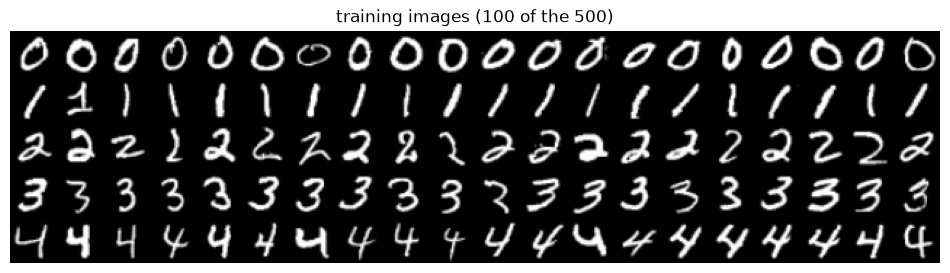

In [5]:
# One training image out of 5
examples = train_dataset.images[::5]

fig, ax = plt.subplots(figsize=(12, 3.2))
show_grid(ax, examples, 20, f"training images ({len(examples)} of the {len(train_dataset)})")
plt.show()

## 3. Model

`code/mymodel.py`

In [6]:
from mymodel import VAE

model = VAE().to(device)
num_parameters = sum(p.numel() for p in model.parameters())

print(model)
print(f"latent dimension     : {model.latent_dim}")
print(f"number of parameters : {num_parameters:,}")

VAE(
  (enc): Sequential(
    (0): Conv2d(1, 8, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    (1): GroupNorm(2, 8, eps=1e-05, affine=True)
    (2): ReLU()
    (3): Conv2d(8, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    (4): GroupNorm(4, 16, eps=1e-05, affine=True)
    (5): ReLU()
    (6): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    (7): GroupNorm(8, 32, eps=1e-05, affine=True)
    (8): ReLU()
    (9): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (10): GroupNorm(16, 64, eps=1e-05, affine=True)
    (11): ReLU()
    (12): Flatten(start_dim=1, end_dim=-1)
  )
  (fc_mu): Linear(in_features=1024, out_features=32, bias=True)
  (fc_logvar): Linear(in_features=1024, out_features=32, bias=True)
  (dec): Sequential(
    (0): Linear(in_features=32, out_features=1024, bias=True)
    (1): ReLU()
    (2): Unflatten(dim=1, unflattened_size=(64, 4, 4))
    (3): ConvTranspose2d(64, 3

In [7]:
# Check the interface of the model on a few images

x = test_dataset.images[:8].to(device)
latent_shape = (8, model.latent_dim)

with torch.no_grad():
    mu, logvar = model.encode(x)
    z = model.reparameterize(mu, logvar)
    x_hat = model.decode(z)
    outputs = model(x)

assert model.latent_dim >= 2, "latent_dim must be at least 2"
assert mu.shape == latent_shape, f"encode: mu has shape {tuple(mu.shape)}, expected {latent_shape}"
assert logvar.shape == latent_shape, f"encode: logvar has shape {tuple(logvar.shape)}, expected {latent_shape}"
assert z.shape == latent_shape, f"reparameterize: z has shape {tuple(z.shape)}, expected {latent_shape}"
assert x_hat.shape == x.shape, f"decode: x_hat has shape {tuple(x_hat.shape)}, expected {tuple(x.shape)}"
assert 0 <= x_hat.min() and x_hat.max() <= 1, "decode: the values of x_hat must be in [0, 1]"
assert len(outputs) == 3, "forward must return (x_hat, mu, logvar)"
assert outputs[0].shape == x.shape, "forward: the first output must be x_hat"
assert outputs[1].shape == outputs[2].shape == latent_shape, "forward: the last two outputs must be mu and logvar"

print("the model has the expected interface")

the model has the expected interface


## 4. Optimizer

`code/myoptim.py`

In [8]:
from myoptim import get_optimizer

optimizer = get_optimizer(model)

print(f"batch size       : {BATCH_SIZE}")
print(f"number of epochs : {NUM_EPOCHS}")
print(optimizer)

batch size       : 32
number of epochs : 263
AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0.0001
)


## 5. Training

`code/mytrain.py`

In [9]:
from mytrain import train_one_epoch

history = {term: [] for term in LOSS_TERMS}

for epoch in range(1, NUM_EPOCHS + 1):
    losses = train_one_epoch(model, optimizer, train_loader, device)
    for term in LOSS_TERMS:
        history[term].append(float(losses[term]))

    if epoch == 1 or epoch == NUM_EPOCHS or epoch % max(1, NUM_EPOCHS // 20) == 0:
        print(f"epoch {epoch:4d}/{NUM_EPOCHS} | loss {losses['loss']:7.2f}"
              f" (recon {losses['recon']:7.2f}, kl {losses['kl']:6.2f})")

# the weights are copied to the CPU, so that the file loads without DirectML
torch.save({k: v.detach().cpu() for k, v in model.state_dict().items()},
           TRAIN_DIR / "model.pt")

c:\Users\josun\Desktop\project-01\.venv\Lib\site-packages\torch\nn\functional.py:3172: UserWarning: The operator 'aten::binary_cross_entropy' is not currently supported on the DML backend and will fall back to run on the CPU. This may have performance implications. (Triggered internally at C:\__w\1\s\pytorch-directml-plugin\torch_directml\csrc\dml\dml_cpu_fallback.cpp:17.)
  return torch._C._nn.binary_cross_entropy(input, target, weight, reduction_enum)


epoch    1/263 | loss  623.89 (recon  620.66, kl   3.22)
epoch   13/263 | loss  266.42 (recon  253.93, kl  12.48)
epoch   26/263 | loss  235.08 (recon  218.63, kl  16.44)
epoch   39/263 | loss  222.82 (recon  205.37, kl  17.45)
epoch   52/263 | loss  214.49 (recon  196.50, kl  17.99)
epoch   65/263 | loss  206.54 (recon  187.25, kl  19.29)
epoch   78/263 | loss  197.33 (recon  177.55, kl  19.79)
epoch   91/263 | loss  182.19 (recon  159.42, kl  22.77)
epoch  104/263 | loss  175.42 (recon  151.26, kl  24.16)
epoch  117/263 | loss  176.03 (recon  151.48, kl  24.55)
epoch  130/263 | loss  172.85 (recon  148.74, kl  24.12)
epoch  143/263 | loss  173.17 (recon  149.20, kl  23.97)
epoch  156/263 | loss  171.23 (recon  147.00, kl  24.23)
epoch  169/263 | loss  170.02 (recon  145.71, kl  24.30)
epoch  182/263 | loss  169.07 (recon  144.33, kl  24.74)
epoch  195/263 | loss  166.42 (recon  142.08, kl  24.34)
epoch  208/263 | loss  168.85 (recon  144.88, kl  23.98)
epoch  221/263 | loss  168.00 (

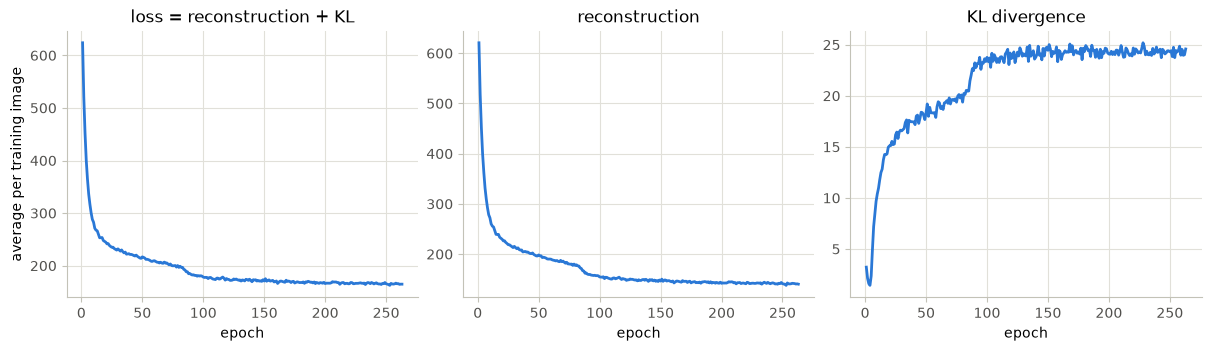

In [10]:
epochs = range(1, NUM_EPOCHS + 1)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), constrained_layout=True)
for ax, (term, title) in zip(axes, LOSS_TERMS.items()):
    ax.plot(epochs, history[term], color=BLUE, linewidth=2)
    ax.set_title(title)
    ax.set_xlabel("epoch")
    style_axes(ax)
axes[0].set_ylabel("average per training image")
save_figure(fig, TRAIN_DIR / "loss.png")

## 6. Sampling

`code/mysample.py`

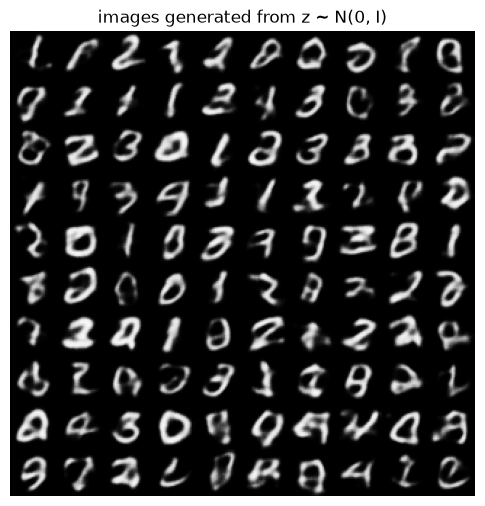

In [11]:
from mysample import sample

samples = sample(model, 100, device)

assert samples.shape == (100, *image_shape), f"sample: output has shape {tuple(samples.shape)}"
assert 0 <= samples.min() and samples.max() <= 1, "sample: the values must be in [0, 1]"

fig, ax = plt.subplots(figsize=(6, 6.3))
show_grid(ax, samples, 10, "images generated from z ~ N(0, I)")
save_figure(fig, SAMPLE_DIR / "sample.png")

## 7. Reconstruction

Test images and their reconstructions: each image is encoded, and the mean of `q(z|x)` is decoded.

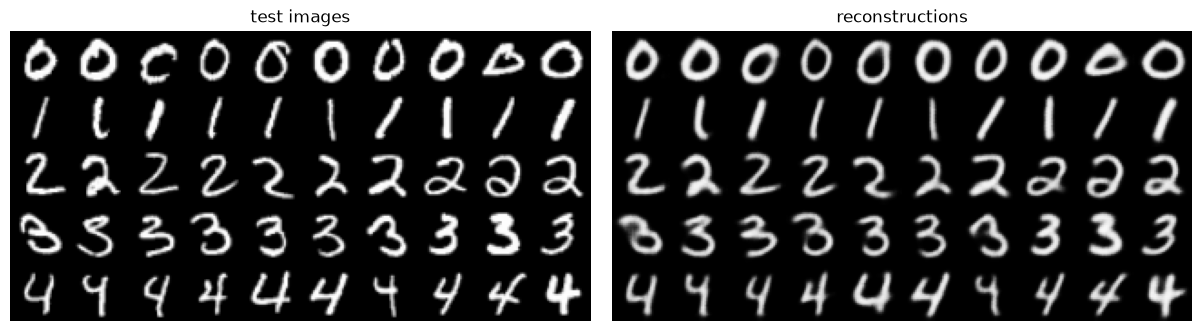

In [12]:
# One test image out of 100
originals = test_dataset.images[::100]

model.eval()
with torch.no_grad():
    mu, _ = model.encode(originals.to(device))
    reconstructions = model.decode(mu).cpu()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.2), constrained_layout=True)
show_grid(axes[0], originals, 10, "test images")
show_grid(axes[1], reconstructions, 10, "reconstructions")
save_figure(fig, RESULT_DIR / "reconstruction.png")

## 8. Results

`util/result.py` (provided) measures the trained model with the 5,000 test images. For both values, lower is better.

- **FID**: distance between the distribution of 5,000 images generated by the model and the distribution of the test images.
- **Reconstruction error**: squared difference between a test image and its reconstruction, summed over the pixels and averaged over the test images.

The first run downloads the network used by the FID (about 100 MB). The cell takes seconds with a GPU, but can take more than 10 minutes with a CPU.

In [13]:
from result import evaluate, save, BATCH_SIZE as EVAL_BATCH, SEED as EVAL_SEED, _to_rgb
import torch.nn.functional as F
from torcheval.metrics.image.fid import FIDInceptionV3


@torch.no_grad()
def evaluate_on_device(model):
    """Same as evaluate of util/result.py, for DirectML: the Inception-v3
    features are computed on the device of the model, their statistics and the
    Frechet distance on the CPU (DirectML has no torch.linalg.eigvals). The
    formulas are those of torcheval's FrechetInceptionDistance, in float32."""
    device = next(model.parameters()).device
    test_images = get_dataset("test").images
    model.eval()

    generator = torch.Generator().manual_seed(EVAL_SEED)
    z = torch.randn(len(test_images), model.latent_dim, generator=generator)

    inception = FIDInceptionV3().to(device).eval().requires_grad_(False)

    def features(images):
        # FIDInceptionV3 enlarges the images to 299 x 299 with bilinear
        # interpolation; it is done here on the CPU, because the bilinear
        # interpolation of DirectML gives different values. The network then
        # runs on the device.
        x = F.interpolate(_to_rgb(images.cpu()), size=(299, 299), mode="bilinear",
                          align_corners=False)
        return inception.model(x.to(device)).cpu().float()

    real_feats, fake_feats = [], []
    squared_error = 0.0

    for x, z_batch in zip(test_images.split(EVAL_BATCH), z.split(EVAL_BATCH)):
        x = x.to(device)

        mu, _ = model.encode(x)
        x_hat = model.decode(mu)
        squared_error += (x - x_hat).pow(2).sum().item()

        samples = model.decode(z_batch.to(device))
        if samples.shape != x.shape:
            raise ValueError(
                f"evaluate: model.decode returns images of shape {tuple(samples.shape)}, "
                f"expected {tuple(x.shape)}")

        real_feats.append(features(x))
        fake_feats.append(features(samples))

    def stats(feats):
        feats = torch.cat(feats)
        n = feats.shape[0]
        mean = (feats.sum(dim=0) / n).unsqueeze(0)
        cov = (feats.T @ feats - n * mean.T @ mean) / (n - 1)
        return mean.squeeze(0), cov

    real_mean, real_cov = stats(real_feats)
    fake_mean, fake_cov = stats(fake_feats)
    diff = (real_mean - fake_mean).square().sum()
    trace = real_cov.trace() + fake_cov.trace()
    sqrt_eig = torch.linalg.eigvals(real_cov @ fake_cov).sqrt().real.sum()

    return {
        "fid": (diff + trace - 2 * sqrt_eig).item(),
        "reconstruction_error": squared_error / len(test_images),
    }


result = evaluate_on_device(model) if USE_DML else evaluate(model)
result_file = save(result, info)

print(f"name                 : {info['name']}")
print(f"student ID           : {info['student_id']}")
print(f"batch size           : {BATCH_SIZE}")
print(f"number of epochs     : {NUM_EPOCHS}")
print(f"latent dimension     : {model.latent_dim}")
print(f"number of parameters : {num_parameters:,}")
print() 
print(f"FID                  : {result['fid']:.2f}")
print(f"reconstruction error : {result['reconstruction_error']:.2f}")
print()
print(f"saved {result_file}")

name                 : Sung Cho
student ID           : 20214904
batch size           : 32
number of epochs     : 263
latent dimension     : 32
number of parameters : 163,561

FID                  : 39.60
reconstruction error : 8.11

saved C:\Users\josun\Desktop\project-01\result\result_20214904_Sung_Cho.csv
